In [5]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind")

A base mtcars reúne 32 modelos de carro vendidos nos Estados Unidos em 1973 e 1974.

mpg	Consumo, em milhas por galão. Quanto maior, mais econômico
am	Câmbio: 0 = automático, 1 = manual

In [13]:
# Carrega a base e cria o rótulo do câmbio com comandos encadeados
mtcars = (
    pd.read_csv("../../data/mtcars.csv")
    .assign(
        transmission=lambda df: np.where(
            df["am"] == 1,
            "Manual",
            "Automático",
        ),
    )
)

mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,Manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,Manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,Manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,Automático
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,Automático


**.assign()**  É uma função do pandas usada para criar novas colunas (ou substituir as existentes). Ela retorna um novo DataFrame com as alterações, deixando o DataFrame original completamente inalterado.

**lambda df:**  Função anônima (uma função rápida, de uma linha só, que não precisa receber um nome).

**np.where**  Escolhe o rótulo linha a linha




**# Equivalente a:**

Ler o CSV e salva na variável no mtcars
mtcars = pd.read_csv("mtcars/data/mtcars.csv")

Criar a nova coluna usando a variável que acabou de ser criada
mtcars["transmission"] = np.where(mtcars["am"] == 1, "Manual", "Automático")


##############################################

# Medindo efeito aparente: Δobs

**Resumo inicial da distribuição:**

In [18]:
# Tamanho, média, mediana e desvio-padrão do consumo por câmbio
(
    mtcars
    .groupby("transmission")
    .mpg
    .agg(["size", "mean", "median", "std"])
    .round(2)
)

,size,mean,median,std
transmission,,,,
Automático,19,17.15,17.3,3.83
Manual,13,24.39,22.8,6.17


**Δobs**

In [21]:
# Efeito observado: diferença das médias de consumo
manual = mtcars.loc[mtcars.am == 1, "mpg"]
automatico = mtcars.loc[mtcars.am == 0, "mpg"]

delta_obs = manual.mean() - automatico.mean()

print(f"Delta: {delta_obs:.2}")

Delta: 7.2


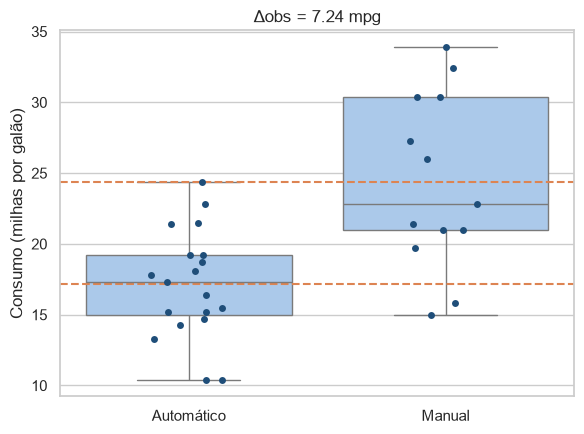

In [24]:
# Boxplot com as observações sobrepostas e as médias de cada grupo
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):
    sns.boxplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#A1C9F4",
        showfliers=False,
    )
    sns.stripplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#1F4E79", alpha=alpha, jitter=jitter,
    )


#
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["Automático", "Manual"], ax)
for mean in [automatico.mean(), manual.mean()]:
    ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="",
       ylabel="Consumo (milhas por galão)")
plt.tight_layout()
plt.show()